### Filter-Based Feature Selection

#### What is Feature Selection ?

- **Feature selection** is the process of choosing useful input features and removing features that are irrelevant, redundant, or unhelpful for a machine learning task.
- The goal is to keep a smaller, more useful set of features without unnecessarily losing predictive information.
- Fewer features can make a model simpler, faster to train, easier to interpret, and sometimes less prone to overfitting.

#### What is Filter-Based Feature Selection ?

- **Filter methods** select features using statistical properties of the data, before training a machine learning model.
- They do not depend on a particular model's training process.
- Common filter methods include duplicate-feature removal, variance threshold, correlation analysis, ANOVA F-test, and Chi-Square test.

#### Why do we use it ?

- To remove duplicate or nearly redundant information.
- To remove features with very little variation.
- To reduce strong correlations between input features.
- To identify features that have a statistical relationship with the target.
- To reduce training time and make a model easier to work with.

#### Important workflow rule: avoid data leakage

Split the data into training and testing sets **before** learning which features to keep. Fit selection rules (such as variance threshold, correlation filtering, and ANOVA) using training data only, then apply the learned selection to the test data. The test set should remain unseen until final evaluation.

This notebook uses Logistic Regression for a Human Activity Recognition classification task, compares a baseline model with a model after feature selection, and then demonstrates Chi-Square tests on Titanic data.


In [1]:
import numpy as np 
import pandas as pd 

In [2]:
# Kaggle Link (Dataset): https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones?select=train.csv
df = pd.read_csv('Datasets/train.csv').drop(columns='subject')

In [3]:
df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


In [4]:
df.shape

(7352, 562)

In [5]:
df['Activity'].value_counts()

Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

In [6]:
df.columns

Index(['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
       'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z',
       'tBodyAcc-max()-X',
       ...
       'fBodyBodyGyroJerkMag-skewness()', 'fBodyBodyGyroJerkMag-kurtosis()',
       'angle(tBodyAccMean,gravity)', 'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)', 'Activity'],
      dtype='object', length=562)

### Establish a Baseline: Logistic Regression Without Feature Selection

Before removing any features, the notebook trains Logistic Regression using the original feature set.

- `X` contains the input features and `y` contains the target class (`Activity`).
- `LabelEncoder` converts the activity labels into numeric class identifiers.
- `train_test_split` creates training and testing sets.
- The model is fitted on the training set and evaluated using test accuracy.

**Why create a baseline ?**

It gives us a reference score. After feature selection, we can compare the new model with this baseline to see whether using fewer features maintains or improves test performance.

Accuracy alone may not tell the whole story, especially if classes are imbalanced. A confusion matrix, precision, recall, and F1-score can provide additional insight.


In [7]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [8]:
# seprate feature and target 
X = df.drop('Activity', axis=1)
y = df['Activity']

In [9]:
# Encode the target labels
le = LabelEncoder()
y = le.fit_transform(y)

In [10]:
# spilt data into training  and testing sets 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
print(X_train.shape)
print(X_test.shape)

(5881, 561)
(1471, 561)


In [12]:
# Apply Losgistic Regression 
log_reg = LogisticRegression(max_iter=1000) 

In [13]:
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [14]:
# make predictions 
y_pred = log_reg.predict(X_test)

In [15]:
accuracy_score(y_test, y_pred)

0.9809653297076818

### 1. Remove Duplicate Columns

**What does it do ?**

- Duplicate columns contain exactly the same values for every row.
- Keeping multiple copies adds no new information and can make the feature set unnecessarily large.
- The custom `get_duplicate_cols()` function hashes each column's values and groups columns that have matching hashes.
- The notebook then removes the repeated columns from both `X_train` and `X_test`.

**Why remove duplicates ?** 

Duplicate features are perfectly redundant. Removing them makes the dataset smaller without losing information represented by those duplicated columns.

**Points to remember**

- This method detects exact duplicates, not columns that are merely highly correlated.
- The same columns must be removed from both training and testing data.
- The code identifies duplicates in the training set and applies that decision to the test set, which keeps the test data out of the selection decision.


In [16]:
def get_duplicate_cols(df): 
    duplicate_cols = {}  # Dictionary to store duplicate columns
    seen_cols = {}  # Dictionary to store hashes of seen columns

    for col in df.columns: 
        current_col = df[col] 

        # Convert column data into bytes for hashing
        try: 
            current_col_hash = current_col.values.tobytes()
        except AttributeError: 
            current_col_hash = current_col.to_string().encode()

        if current_col_hash in seen_cols: 
            first_col = seen_cols[current_col_hash]  # The first column found with this hash
            
            if first_col in duplicate_cols:  
                duplicate_cols[first_col].append(col)  # Append duplicate column
            else:  
                duplicate_cols[first_col] = [col]  # Create a list with first duplicate
        else:
            seen_cols[current_col_hash] = col  # Store the column hash

    return duplicate_cols


In [17]:
duplicate_cols = get_duplicate_cols(X_train)
duplicate_cols

{'tBodyAccMag-mean()': ['tBodyAccMag-sma()',
  'tGravityAccMag-mean()',
  'tGravityAccMag-sma()'],
 'tBodyAccMag-std()': ['tGravityAccMag-std()'],
 'tBodyAccMag-mad()': ['tGravityAccMag-mad()'],
 'tBodyAccMag-max()': ['tGravityAccMag-max()'],
 'tBodyAccMag-min()': ['tGravityAccMag-min()'],
 'tBodyAccMag-energy()': ['tGravityAccMag-energy()'],
 'tBodyAccMag-iqr()': ['tGravityAccMag-iqr()'],
 'tBodyAccMag-entropy()': ['tGravityAccMag-entropy()'],
 'tBodyAccMag-arCoeff()1': ['tGravityAccMag-arCoeff()1'],
 'tBodyAccMag-arCoeff()2': ['tGravityAccMag-arCoeff()2'],
 'tBodyAccMag-arCoeff()3': ['tGravityAccMag-arCoeff()3'],
 'tBodyAccMag-arCoeff()4': ['tGravityAccMag-arCoeff()4'],
 'tBodyAccJerkMag-mean()': ['tBodyAccJerkMag-sma()'],
 'tBodyGyroMag-mean()': ['tBodyGyroMag-sma()'],
 'tBodyGyroJerkMag-mean()': ['tBodyGyroJerkMag-sma()'],
 'fBodyAccMag-mean()': ['fBodyAccMag-sma()'],
 'fBodyBodyAccJerkMag-mean()': ['fBodyBodyAccJerkMag-sma()'],
 'fBodyBodyGyroMag-mean()': ['fBodyBodyGyroMag-sma()'

In [18]:
# See the v
X_train[['tBodyAccMag-mean()', 'tBodyAccMag-sma()', 'tGravityAccMag-mean()' ,'tGravityAccMag-sma()']]

,tBodyAccMag-mean(),tBodyAccMag-sma(),tGravityAccMag-mean(),tGravityAccMag-sma()
57,-0.997420,-0.997420,-0.997420,-0.997420
4154,-0.133797,-0.133797,-0.133797,-0.133797
6945,0.130528,0.130528,0.130528,0.130528
527,-0.955222,-0.955222,-0.955222,-0.955222
4196,-0.992499,-0.992499,-0.992499,-0.992499
...,...,...,...,...
5191,-0.372758,-0.372758,-0.372758,-0.372758
5226,-0.256033,-0.256033,-0.256033,-0.256033
5390,-0.434138,-0.434138,-0.434138,-0.434138
860,-0.983969,-0.983969,-0.983969,-0.983969


In [19]:
for one_list in duplicate_cols.values():
    X_train.drop(columns=one_list, inplace=True)
    X_test.drop(columns=one_list, inplace=True)

In [20]:
print(X_train.shape)
print(X_test.shape)

(5881, 540)
(1471, 540)


In [21]:
# Here we remove 21 duplicated columns.

### 2. Variance Threshold

**What does it do ?**

- Variance measures how much a feature's values differ from one another.
- A feature with zero variance has the same value in every training row and cannot help distinguish observations.
- `VarianceThreshold(threshold=0.05)` removes features whose training variance is below the chosen threshold.
- `get_support()` identifies which features are retained. The same fitted selector transforms both `X_train` and `X_test`.

**Why use it?** 

It is a simple way to remove constant or near-constant features before model training.

**Points to consider**

- It is an unsupervised filter: it does not look at the target variable.
- A low-variance feature can still be useful for predicting the target.
- The threshold is a choice, not a universal rule.
- Variance depends on feature scale. If features use different units or ranges, scaling and the meaning of the threshold need consideration.
- It does not detect interactions between features.


In [22]:
from sklearn.feature_selection import VarianceThreshold
sel = VarianceThreshold(threshold=0.05)

In [23]:
sel.fit(X_train)

VarianceThreshold(threshold=0.05)

In [24]:
# all have value greater to Threshold
sel.get_support().sum()

np.int64(349)

In [25]:
columns = X_train.columns[sel.get_support()]

In [26]:
columns.shape

(349,)

In [27]:
# delete the cols jinka threshold define trheshold se kam h
X_train = sel.transform(X_train)
X_test = sel.transform(X_test)

In [28]:
X_train = pd.DataFrame(X_train, columns=columns)
X_test = pd.DataFrame(X_test, columns=columns)

In [29]:
X_train.shape

(5881, 349)

In [30]:
X_train

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,-0.994425,-0.994873,-0.994886,-0.994939,-0.993994,-0.995450,-0.938974,-0.577031,-0.813863,0.846922,...,0.394506,-0.684497,-0.901888,0.751089,0.626432,0.263401,-0.646225,0.398881,-0.546717,-0.431200
1,-0.326331,0.069663,-0.224321,-0.343326,0.039623,-0.256327,-0.310961,0.085617,-0.411806,0.271334,...,0.052089,-0.131946,-0.591721,0.628099,-0.357089,-0.925512,0.110212,-0.474013,0.383162,0.238969
2,-0.026220,-0.032163,0.393109,-0.118256,-0.030279,0.432861,0.370607,-0.072309,0.200747,0.118277,...,-0.038923,-0.643660,-0.935668,-0.182993,0.484857,-0.961034,0.147325,-0.819001,0.221549,-0.003571
3,-0.981092,-0.901124,-0.960423,-0.984417,-0.901405,-0.965788,-0.922291,-0.524676,-0.807362,0.825370,...,-0.145084,-0.326860,-0.645937,0.205896,-0.168239,-0.197557,0.328892,-0.744428,0.274256,0.031246
4,-0.997380,-0.983893,-0.984482,-0.997331,-0.985196,-0.983768,-0.942062,-0.564033,-0.810993,0.853330,...,0.096524,-0.113724,-0.445144,-0.267371,-0.304399,-0.081555,0.110146,-0.615329,0.322236,0.161577
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,-0.555352,-0.104055,-0.438064,-0.572530,-0.112149,-0.429688,-0.479744,-0.077885,-0.373579,0.454289,...,0.022624,0.417731,0.200267,-0.155279,-0.137981,0.929236,-0.583898,-0.703989,0.159112,-0.185944
5877,-0.290043,-0.212102,-0.469731,-0.307317,-0.209558,-0.528635,-0.283244,-0.017039,-0.123285,0.123907,...,-0.039773,-0.021970,-0.360982,-0.019533,-0.896005,-0.039591,0.494178,-0.670139,0.106156,-0.220746
5878,-0.627198,-0.216566,-0.424764,-0.648666,-0.253814,-0.417569,-0.547082,-0.236201,-0.441355,0.530629,...,0.094031,0.527152,0.348736,-0.414621,-0.488542,0.095895,-0.297162,-0.856512,0.183547,-0.034939
5879,-0.994825,-0.985314,-0.965857,-0.995170,-0.984285,-0.963293,-0.937503,-0.570198,-0.805684,0.849776,...,0.539885,-0.889671,-0.984051,-0.079515,0.014291,-0.290347,0.602344,-0.839693,0.081388,-0.098270


In [31]:
print(X_train.shape)
print(X_test.shape)

(5881, 349)
(1471, 349)


In [32]:
# here we remove 191 cols 

### 3. Correlation-Based Feature Selection

**What does it do ?**

- Correlation measures the strength and direction of a linear relationship between two numeric features.
- The notebook calculates a feature-correlation matrix and removes one feature from a pair when the correlation is greater than `0.95`.
- This is intended to reduce redundant information among highly correlated predictors.

**How to read correlation**

- Close to `+1`: strong positive linear relationship.
- Close to `-1`: strong negative linear relationship.
- Close to `0`: little or no linear relationship (a nonlinear relationship may still exist).

**Important limitation in this notebook:** the code checks only `correlation > 0.95`, so it catches highly positive correlations but does not catch highly negative correlations. If the goal is to detect strong relationships in either direction, use the absolute correlation: `abs(correlation) > 0.95`.

Correlation filtering also has limitations:
- It examines pairs of features, not all possible multivariable dependencies.
- It does not use the target variable.
- A correlated feature may still contain useful information.
- The choice of which feature to drop should consider domain knowledge and model performance.

The correlation matrix is calculated from `X_train`, and the selected columns are then removed from both training and test sets.


In [33]:
import seaborn as sns
import matplotlib.pyplot as plt 

<Axes: >

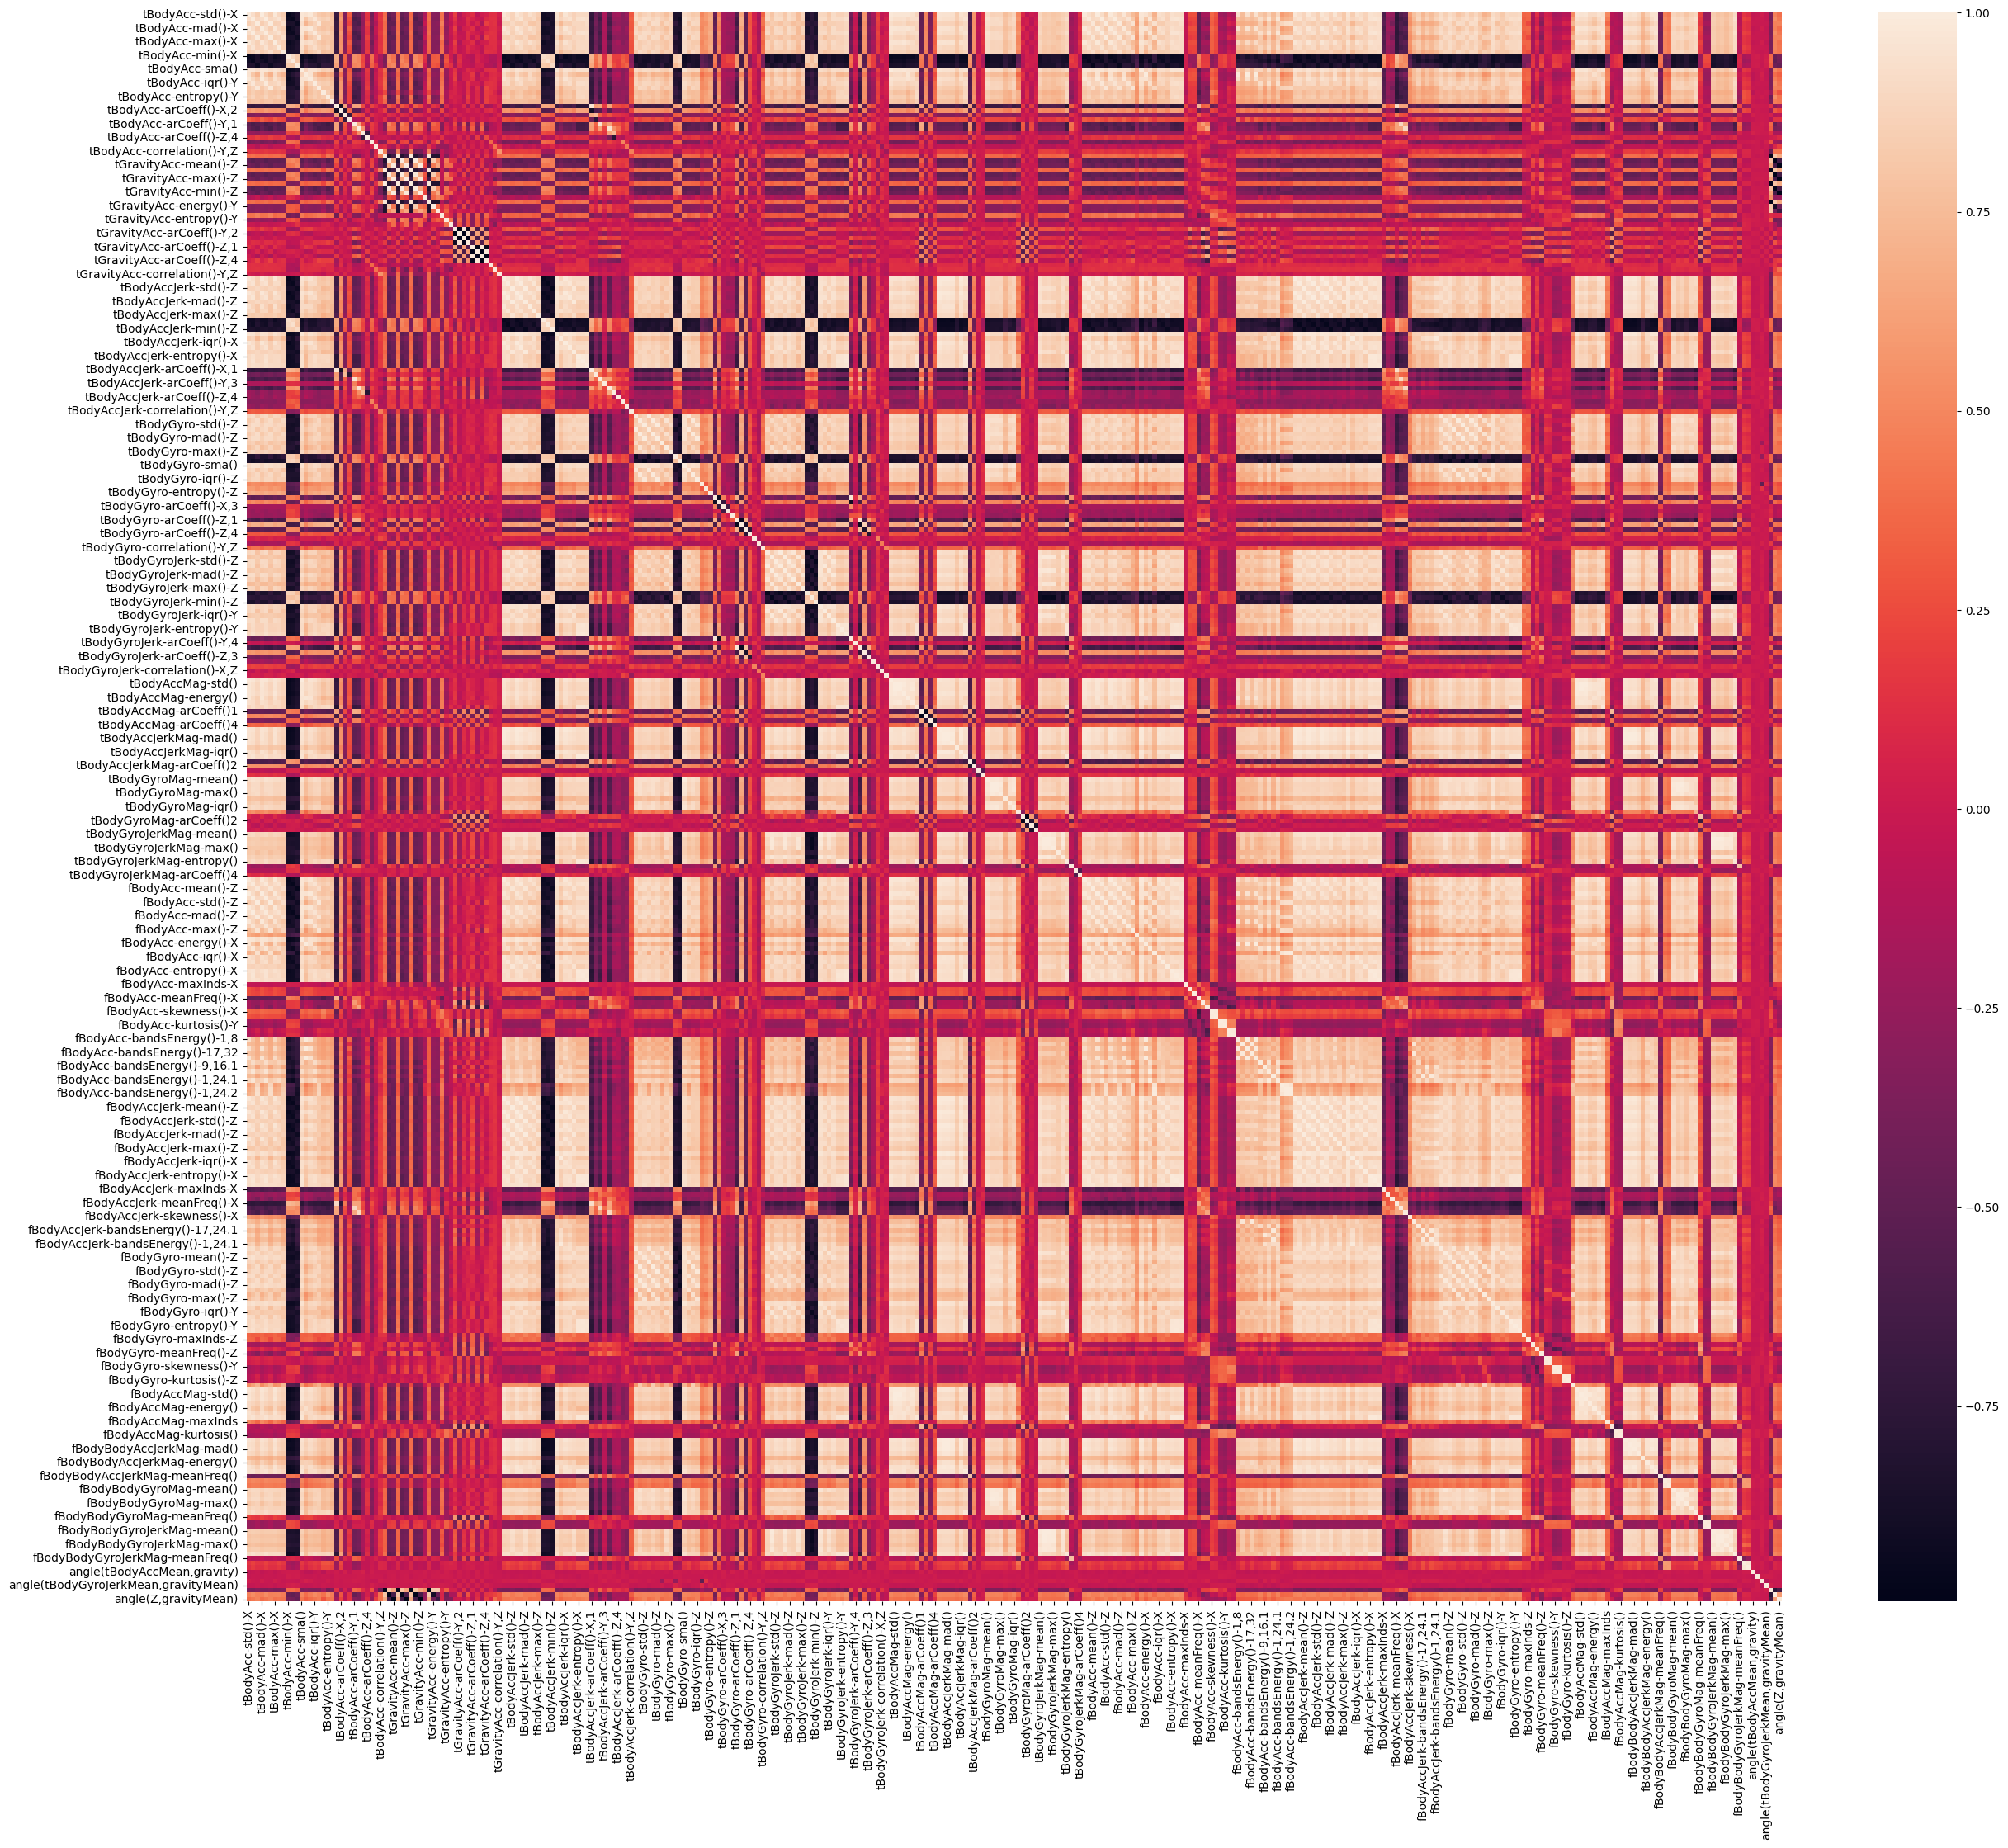

In [34]:
plt.figure(figsize=(30,25))
sns.heatmap(X_train.corr())

In [35]:
corr_matrix = X_train.corr()

In [36]:
corr_matrix

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
tBodyAcc-std()-X,1.000000,0.927247,0.850268,0.998631,0.920936,0.845200,0.981284,0.893743,0.843918,-0.966714,...,-0.061190,0.152159,0.118286,-0.042353,-0.027089,0.023914,-0.035176,-0.374114,0.472605,0.393209
tBodyAcc-std()-Y,0.927247,1.000000,0.895065,0.922627,0.997384,0.894128,0.917831,0.953852,0.882782,-0.937472,...,-0.103492,0.210313,0.179834,-0.023759,-0.012484,-0.002241,-0.028881,-0.383095,0.524945,0.432180
tBodyAcc-std()-Z,0.850268,0.895065,1.000000,0.842986,0.890973,0.997414,0.852711,0.864716,0.936311,-0.861033,...,-0.095347,0.157032,0.124579,-0.009647,-0.020843,-0.010535,-0.016002,-0.344114,0.475241,0.480824
tBodyAcc-mad()-X,0.998631,0.922627,0.842986,1.000000,0.916201,0.838010,0.973704,0.888702,0.838024,-0.962447,...,-0.055098,0.153494,0.120750,-0.049949,-0.026887,0.024098,-0.035629,-0.370629,0.467965,0.389139
tBodyAcc-mad()-Y,0.920936,0.997384,0.890973,0.916201,1.000000,0.890707,0.911283,0.950131,0.877793,-0.932521,...,-0.101235,0.205346,0.175966,-0.027747,-0.011823,-0.005865,-0.026679,-0.379578,0.526803,0.430548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"angle(tBodyGyroMean,gravityMean)",0.023914,-0.002241,-0.010535,0.024098,-0.005865,-0.014838,0.029230,-0.000207,-0.023622,-0.008700,...,-0.024274,0.031310,0.021829,-0.006297,0.013870,1.000000,-0.104987,-0.009878,-0.006218,-0.011178
"angle(tBodyGyroJerkMean,gravityMean)",-0.035176,-0.028881,-0.016002,-0.035629,-0.026679,-0.016949,-0.038935,-0.013144,-0.011510,0.030630,...,-0.000472,-0.030566,-0.028829,-0.025656,0.030850,-0.104987,1.000000,0.027310,-0.009582,-0.009311
"angle(X,gravityMean)",-0.374114,-0.383095,-0.344114,-0.370629,-0.379578,-0.346350,-0.386159,-0.373556,-0.345776,0.365571,...,0.077000,-0.086273,-0.081381,0.012546,0.022038,-0.009878,0.027310,1.000000,-0.784098,-0.642642
"angle(Y,gravityMean)",0.472605,0.524945,0.475241,0.467965,0.526803,0.476498,0.482312,0.489971,0.462052,-0.471464,...,-0.093215,0.086150,0.078420,-0.003872,-0.005159,-0.006218,-0.009582,-0.784098,1.000000,0.596205


In [37]:
columns = corr_matrix.columns

cols_to_drop = []

for i in range(len(columns)): 
    for j in range(i+1, len(columns)): 
        if corr_matrix.loc[columns[i], columns[j]] > 0.95: 
            cols_to_drop.append(columns[j])

print(len(cols_to_drop))

1508


**Optional improvement:** To catch both strong positive and strong negative correlations, use this condition when building the list of columns to remove:

```python
if abs(corr_matrix.loc[columns[i], columns[j]]) > 0.95:
    cols_to_drop.append(columns[j])
```

This is a pairwise heuristic. Review which feature is removed rather than automatically dropping a column without considering its meaning.


In [38]:
cols_to_drop = set(cols_to_drop)
len(cols_to_drop)

197

In [39]:
X_train.drop(columns=cols_to_drop, axis=1, inplace=True)
X_test.drop(columns=cols_to_drop, axis=1, inplace=True)

In [40]:
print(X_train.shape)
print(X_test.shape)

(5881, 152)
(1471, 152)


In [41]:
# here we remove 197 cols 

### 4. ANOVA F-Test (SelectKBest)

**What is ANOVA feature selection ?**

- ANOVA stands for **Analysis of Variance**.
- In classification feature selection, `f_classif` computes an F-statistic for each numeric feature to assess whether its mean differs across target classes.
- `SelectKBest(f_classif, k=100)` keeps the 100 features with the highest F-scores.
- The selector is fitted using `X_train` and `y_train`, then the same selected columns are applied to `X_test`.

**How to interpret the F-score**

- A larger F-score indicates stronger evidence that the feature's mean differs across at least some target classes.
- The F-score is a univariate score: each feature is assessed individually.
- It does not measure feature interactions and does not establish causation.

**Points to remember**

- `f_classif` is intended for classification targets and numeric input features.
- It evaluates features one at a time, so a feature that is useful only through an interaction may be missed.
- It relies on assumptions behind the ANOVA F-test; unusual distributions, unequal variances, or outliers can affect the result.
- Choose `k` based on validation performance and practical needs; `100` is not a universal best value.


In [42]:
from sklearn.feature_selection import f_classif, SelectKBest

In [43]:
sel = SelectKBest(f_classif, k=100)

In [44]:
sel.fit(X_train, y_train)

SelectKBest(k=100)

In [45]:
# display selected features names 
X_train.columns[sel.get_support()]

Index(['tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-max()-Z', 'tBodyAcc-min()-X', 'tBodyAcc-min()-Y',
       'tBodyAcc-min()-Z', 'tBodyAcc-entropy()-X', 'tBodyAcc-entropy()-Y',
       'tBodyAcc-entropy()-Z', 'tBodyAcc-arCoeff()-X,1',
       'tBodyAcc-arCoeff()-X,2', 'tBodyAcc-arCoeff()-X,3',
       'tBodyAcc-arCoeff()-Y,1', 'tBodyAcc-arCoeff()-Z,1',
       'tBodyAcc-correlation()-X,Y', 'tBodyAcc-correlation()-Y,Z',
       'tGravityAcc-mean()-X', 'tGravityAcc-mean()-Y', 'tGravityAcc-mean()-Z',
       'tGravityAcc-sma()', 'tGravityAcc-energy()-Y', 'tGravityAcc-energy()-Z',
       'tGravityAcc-entropy()-X', 'tGravityAcc-entropy()-Y',
       'tGravityAcc-arCoeff()-Y,1', 'tGravityAcc-arCoeff()-Y,2',
       'tGravityAcc-arCoeff()-Z,1', 'tGravityAcc-arCoeff()-Z,2',
       'tGravityAcc-correlation()-Y,Z', 'tBodyAccJerk-std()-Z',
       'tBodyAccJerk-min()-X', 'tBodyAccJerk-min()-Y', 'tBodyAccJerk-min()-Z',
       'tBodyAccJerk-entropy()-X', 'tBodyAccJerk-arCoeff

In [46]:
columns = X_train.columns[sel.get_support()]

In [47]:
X_train = sel.transform(X_train)
X_test = sel.transform(X_test)

In [48]:
X_train = pd.DataFrame(X_train, columns=columns)
X_test = pd.DataFrame(X_test, columns=columns)

In [49]:
print(X_train.shape)
print(X_test.shape)

(5881, 100)
(1471, 100)


### Compare the Model After Feature Selection

The notebook now trains Logistic Regression using the reduced feature set and evaluates it on the held-out test set.

Compare this accuracy with the baseline accuracy from the beginning of the notebook.

- If accuracy stays similar while many features are removed, feature selection may have made the model more compact without much loss in performance.
- If accuracy improves, removing noisy or redundant features may have helped.
- If accuracy falls, some removed features may have contained useful information.

For a fair comparison, use the same train/test split and evaluation metric. Ideally, choose the number of features and thresholds using cross-validation on the training data, not by repeatedly checking the test score.


In [50]:
log_reg = LogisticRegression(max_iter=1000) 
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [51]:
y_pred = log_reg.predict(X_test)

In [52]:
accuracy_score(y_test, y_pred)

0.9687287559483345

### 5. Chi-Square Feature Selection

**What is the Chi-Square test ?**

- The Chi-Square ($\chi^2$) test is a statistical test used to examine whether two categorical variables are associated.
- In feature selection for classification, it can help identify categorical or non-negative count-like features that have an association with the target class.
- The notebook demonstrates the test using Titanic features and the `Survived` target.

**How does it work ?**

1. Build a contingency table showing the counts for combinations of feature categories and target categories.
2. Compare the observed counts with the counts expected if the variables were independent.
3. Calculate a Chi-Square statistic and p-value.
4. A small p-value (commonly below 0.05) is evidence against independence between the feature and target.

**How to interpret the p-value**

- Small p-value: evidence that the feature and target are associated.
- Large p-value: insufficient evidence of an association in this sample.
- A p-value does not measure the strength or practical importance of an association, and it does not prove causation.

**Important details**

- `chi2_contingency()` should receive the contingency table without totals/margins. The `margins=True` option is useful for displaying totals, but those totals must not be included in the test.
- Scikit-learn's `sklearn.feature_selection.chi2` expects non-negative feature values. It is commonly used with non-negative counts or one-hot encoded categorical features.
- Applying `LabelEncoder` to nominal categories assigns arbitrary integer codes. Those codes should not be treated as meaningful numeric magnitudes; one-hot encoding is usually more appropriate for nominal categorical predictors.
- The Chi-Square test is sensitive to small expected cell counts. If expected counts are too small, consider combining categories where substantively justified or using an appropriate exact test.


In [57]:
titanic = pd.read_csv('Datasets/titanic.csv')[['Pclass', 'Sex', 'Parch', 'SibSp','Embarked', 'Survived']]

In [58]:
titanic.head()

,Pclass,Sex,Parch,SibSp,Embarked,Survived
0,3,male,0,1,S,0
1,1,female,0,1,C,1
2,3,female,0,0,S,1
3,1,female,0,1,S,1
4,3,male,0,0,S,0


In [59]:
ct = pd.crosstab(titanic['Survived'], titanic['Sex'], margins=True)
ct

Sex,female,male,All
Survived,,,
0,81,468,549
1,233,109,342
All,314,577,891


In [60]:
# Correct Chi-Square test: do not include row/column totals in the test
from scipy.stats import chi2_contingency

ct_for_test = pd.crosstab(titanic['Survived'], titanic['Sex'])
chi2_stat, p_value, degrees_of_freedom, expected = chi2_contingency(ct_for_test)

print("Contingency table:")
display(ct_for_test)

print(f"Chi-Square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"P-value: {p_value:.6g}")

# A small p-value (for example, < 0.05) is evidence of an association
# between Sex and Survived in this sample.


Contingency table:


Sex,female,male
Survived,,
0,81,468
1,233,109


Chi-Square statistic: 260.7170
Degrees of freedom: 1
P-value: 1.19736e-58


In [61]:
scores = [] 

for feature in titanic.columns[:-1]: 

    ct = pd.crosstab(titanic['Survived'], titanic[feature])

    # chi_test 
    p_value = chi2_contingency(ct)[1] 
    scores.append(p_value)

In [62]:
scores

[np.float64(4.549251711298793e-23),
 np.float64(1.1973570627755645e-58),
 np.float64(9.703526421039996e-05),
 np.float64(1.5585810465902118e-06),
 np.float64(1.769922284120912e-06)]

<Axes: >

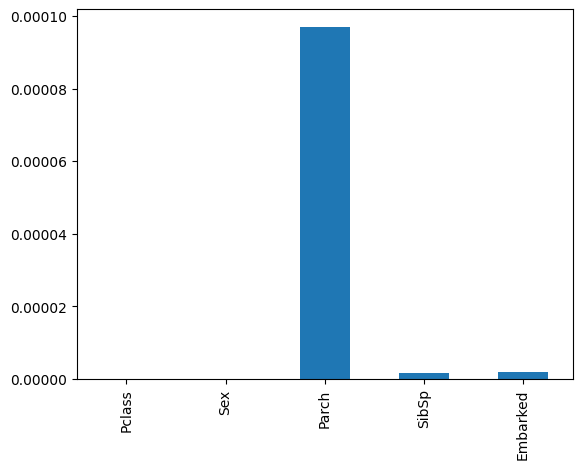

In [63]:
pd.Series(scores, index=titanic.columns[:-1]).plot(kind='bar')

Text(0, 0.5, 'P-values')

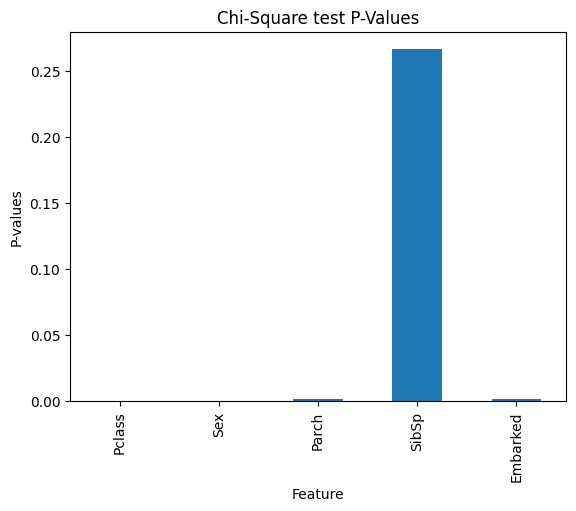

In [64]:
# another way 
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import chi2
import matplotlib.pyplot as plt 

# Encode variables 
le = LabelEncoder() 
titanic_encoded = titanic.apply(le.fit_transform)

X = titanic_encoded.drop('Survived', axis=1)
y = titanic_encoded['Survived']

# calculate chi_sqaured test 
chi_scores = chi2(X,y)

p_value = pd.Series(chi_scores[1], index=X.columns)

p_value.plot.bar()

plt.title("Chi-Square test P-Values")
plt.xlabel('Feature')
plt.ylabel('P-values')

#### Scikit-learn's `chi2` function

The final code cell demonstrates `sklearn.feature_selection.chi2`, which returns a Chi-Square score and p-value for each feature against the target.

For categorical columns such as `Sex` and `Embarked`, prefer one-hot encoding rather than assigning arbitrary integer labels. For example:

```python
X_cat = pd.get_dummies(
    titanic.drop(columns="Survived"),
    columns=["Sex", "Embarked"],
    drop_first=False
)

y = titanic["Survived"]

from sklearn.feature_selection import chi2
chi_scores, p_values = chi2(X_cat, y)

chi_results = pd.DataFrame({
    "Feature": X_cat.columns,
    "Chi2 Score": chi_scores,
    "P-value": p_values
}).sort_values("P-value")

display(chi_results)
```

This produces non-negative indicator columns for categorical levels, which are suitable inputs for the scikit-learn Chi-Square feature score.


### Key Takeaways

1. Filter methods select features using statistical properties before fitting the final model.
2. Remove exact duplicate columns because they add no new information.
3. Variance Threshold removes low-variance features but ignores the target.
4. Correlation filtering reduces highly related predictors; use absolute correlation if both positive and negative relationships matter.
5. ANOVA F-test (`f_classif`) scores numeric features individually according to differences in their means across classes.
6. Chi-Square tests can identify associations between categorical/non-negative features and a classification target.
7. Fit feature-selection rules on training data only, then apply the same selection to test data.
8. Always compare the reduced model with a baseline using held-out data or cross-validation.
